# RAG multimodal agentique — « Attention Is All You Need »

Pipeline complet : extraction PDF (texte + images) → embeddings CLIP → ChromaDB → recherche multimodale → `retriever_tool` → agent ReAct LangGraph → tests.

**Prérequis** : Python 3.10+, une clé API pour le LLM (`ANTHROPIC_API_KEY` par défaut, ou `OPENAI_API_KEY`, ou Ollama en local). Le fichier `Attention is all you need.pdf` est cherché à côté du notebook ; s'il est absent, il est téléchargé depuis arXiv.

In [13]:
%pip install -q pymupdf open_clip_torch torch torchvision chromadb pillow matplotlib numpy \
    langchain-core langgraph langchain-ollama

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\admin\scoop\apps\python\current\python.exe -m pip install --upgrade pip


In [14]:
import os, re, io, hashlib, urllib.request
from pathlib import Path
from typing import Literal, Union

import fitz  # PyMuPDF
import numpy as np
import torch
from PIL import Image
import matplotlib.pyplot as plt

PDF_PATH = Path("Attention is all you need.pdf")
PDF_URL = "https://arxiv.org/pdf/1706.03762"

WORK_DIR = Path("rag_multimodal")
IMG_DIR = WORK_DIR / "images"
DB_DIR = WORK_DIR / "chroma_db"
for d in (IMG_DIR, DB_DIR):
    d.mkdir(parents=True, exist_ok=True)

if not PDF_PATH.exists():
    req = urllib.request.Request(PDF_URL, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req) as r, open(PDF_PATH, "wb") as f:
        f.write(r.read())
print("PDF :", PDF_PATH, f"({PDF_PATH.stat().st_size/1024:.0f} Ko)")

PDF : Attention is all you need.pdf (2163 Ko)


## Étape 1 — Extraction du contenu multimodal

**Texte** : découpage par page puis en chunks de ~60 mots avec chevauchement. Le choix est volontairement court : l'encodeur texte de CLIP est limité à **77 tokens** et tronque le reste silencieusement.

**Images** : on extrait (a) les images raster embarquées et (b) les figures **vectorielles** (les schémas du Transformer sont probablement dessinés en vectoriel, donc invisibles pour `get_images`) en rendant les zones de dessin en PNG.

In [15]:
CHUNK_WORDS, OVERLAP = 60, 15
MIN_IMG_SIZE = 120  # pixels : ignore icônes, filets, puces

def clean(t: str) -> str:
    return re.sub(r"\s+", " ", t.replace("-\n", "")).strip()

def chunk_text(text: str, size=CHUNK_WORDS, overlap=OVERLAP):
    words = text.split()
    step = size - overlap
    return [" ".join(words[i:i + size]) for i in range(0, max(len(words) - overlap, 1), step)]

def extract_text_chunks(pdf_path):
    chunks = []
    with fitz.open(pdf_path) as doc:
        for pno, page in enumerate(doc, start=1):
            text = clean(page.get_text("text"))
            for j, c in enumerate(chunk_text(text)):
                if c.strip():
                    chunks.append({"text": c, "page": pno, "chunk_id": j})
    return chunks

def extract_images(pdf_path, out_dir: Path):
    records, seen = [], set()
    with fitz.open(pdf_path) as doc:
        for pno, page in enumerate(doc, start=1):
            captions = " | ".join(re.findall(r"Figure\s+\d+:[^\n]*", page.get_text("text")))[:300]

            # (a) images raster embarquées
            for idx, img in enumerate(page.get_images(full=True)):
                try:
                    info = doc.extract_image(img[0])
                    pil = Image.open(io.BytesIO(info["image"])).convert("RGB")
                except Exception:
                    continue
                if min(pil.size) < MIN_IMG_SIZE:
                    continue
                h = hashlib.md5(pil.tobytes()).hexdigest()
                if h in seen:
                    continue
                seen.add(h)
                path = out_dir / f"page{pno:02d}_raster{idx}.png"
                pil.save(path)
                records.append({"path": str(path), "page": pno, "kind": "raster", "caption": captions})

            # (b) figures vectorielles : on rend chaque cluster de dessins
            try:
                rects = page.cluster_drawings()
            except Exception:
                rects = []
            for k, r in enumerate(rects):
                if r.width < MIN_IMG_SIZE or r.height < MIN_IMG_SIZE:
                    continue
                clip = fitz.Rect(r.x0 - 4, r.y0 - 4, r.x1 + 4, r.y1 + 4) & page.rect
                pix = page.get_pixmap(clip=clip, dpi=150)
                path = out_dir / f"page{pno:02d}_vector{k}.png"
                pix.save(path)
                records.append({"path": str(path), "page": pno, "kind": "vector", "caption": captions})
    return records

text_chunks = extract_text_chunks(PDF_PATH)
image_records = extract_images(PDF_PATH, IMG_DIR)
print(f"{len(text_chunks)} chunks de texte | {len(image_records)} images")
print("Exemple de chunk :", text_chunks[5])

138 chunks de texte | 8 images
Exemple de chunk : {'text': 'tasks by applying it successfully to English constituency parsing both with large and limited training data. ∗Equal contribution. Listing order is random. Jakob proposed replacing RNNs with self-attention and started the effort to evaluate this idea. Ashish, with Illia, designed and implemented the first Transformer models and has been crucially involved in every aspect of this work. Noam proposed scaled', 'page': 1, 'chunk_id': 5}


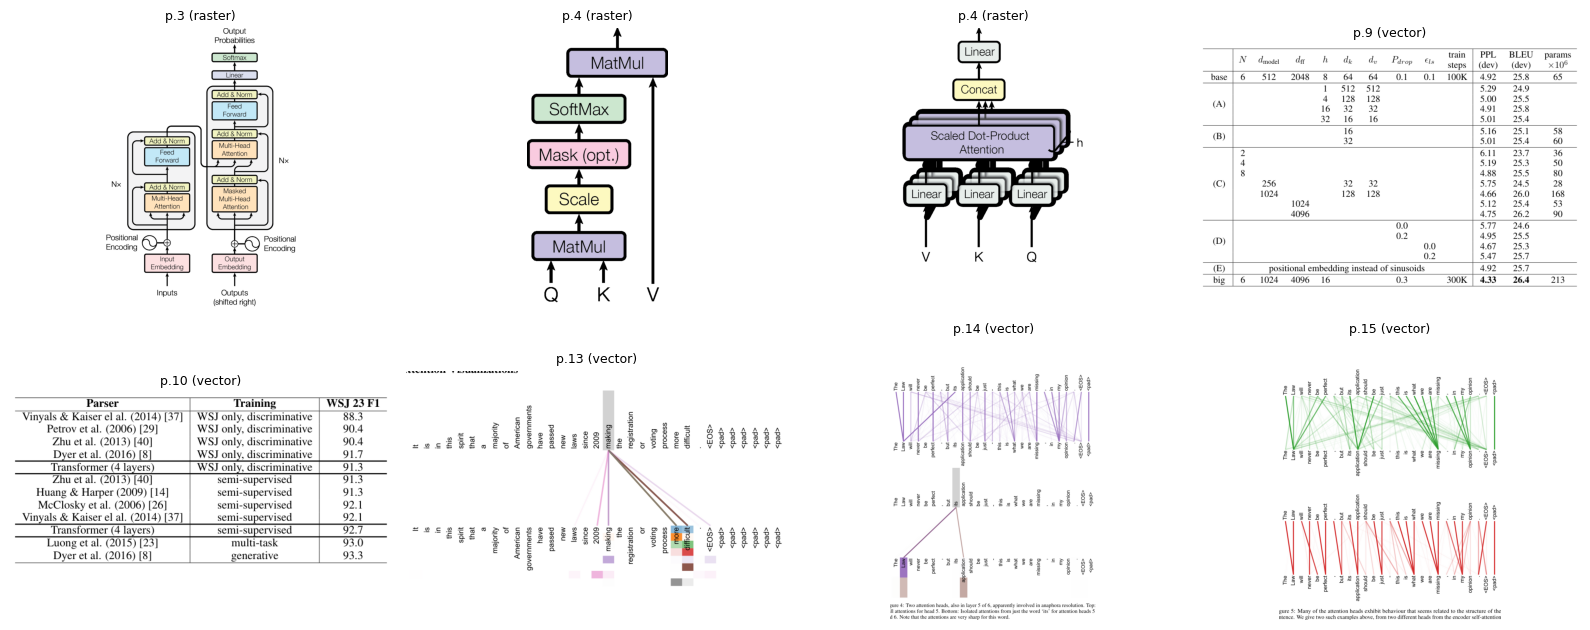

In [16]:
# Contrôle visuel des images extraites
n = len(image_records)
if n:
    cols = min(4, n); rows = -(-n // cols)
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3.2 * rows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, rec in zip(axes.ravel(), image_records):
        ax.imshow(Image.open(rec["path"])); ax.set_title(f"p.{rec['page']} ({rec['kind']})", fontsize=9)
    plt.tight_layout(); plt.show()
else:
    print("Aucune image détectée : vérifier le PDF ou baisser MIN_IMG_SIZE.")

## Étape 2 — Embeddings CLIP (espace latent commun)

CLIP ViT-B-32 (poids `laion2b_s34b_b79k`) encode texte et images dans le même espace de dimension 512. Les vecteurs sont **normalisés L2** : le produit scalaire devient alors égal à la similarité cosinus.

In [17]:
import open_clip

device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
model, _, preprocess = open_clip.create_model_and_transforms("ViT-B-32", pretrained="laion2b_s34b_b79k")
tokenizer = open_clip.get_tokenizer("ViT-B-32")
model = model.to(device).eval()
print("Device :", device)

def _l2(x: torch.Tensor) -> torch.Tensor:
    return x / x.norm(dim=-1, keepdim=True)

@torch.no_grad()
def embed_texts(texts, batch_size=64) -> np.ndarray:
    out = []
    for i in range(0, len(texts), batch_size):
        tok = tokenizer(texts[i:i + batch_size]).to(device)  # tronque à 77 tokens
        out.append(_l2(model.encode_text(tok)).cpu().numpy())
    return np.vstack(out).astype("float32")

@torch.no_grad()
def embed_images(images, batch_size=32) -> np.ndarray:
    """images : liste de chemins (str/Path) ou d'objets PIL.Image."""
    out = []
    for i in range(0, len(images), batch_size):
        batch = []
        for im in images[i:i + batch_size]:
            pil = im if isinstance(im, Image.Image) else Image.open(im)
            batch.append(preprocess(pil.convert("RGB")))
        out.append(_l2(model.encode_image(torch.stack(batch).to(device))).cpu().numpy())
    return np.vstack(out).astype("float32")

# Vérification : dimension et norme unitaire
e = embed_texts(["self-attention"])
print(e.shape, "norme =", float(np.linalg.norm(e[0])))

Device : cpu
(1, 512) norme = 1.0


## Étape 3 — Indexation ChromaDB

- `doc_id` = SHA-256 du **contenu** du fichier : si le PDF ne change pas, on n'indexe pas deux fois ; s'il change, l'ancienne version est supprimée puis réindexée.
- Une seule collection contient texte et images ; le champ `type` (`text` / `image`) permet de filtrer.
- Métrique `cosine` (Chroma renvoie une *distance* = 1 − similarité).

In [18]:
import chromadb

def file_sha256(path) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1 << 20), b""):
            h.update(block)
    return h.hexdigest()

chroma_client = chromadb.PersistentClient(path=str(DB_DIR))
collection = chroma_client.get_or_create_collection("pdf_multimodal", metadata={"hnsw:space": "cosine"})

def index_document(pdf_path, text_chunks, image_records, force=False) -> str:
    doc_id = file_sha256(pdf_path)
    already = collection.get(where={"doc_id": doc_id}, limit=1)
    if already["ids"] and not force:
        print(f"Document déjà indexé (sha256={doc_id[:12]}…) → rien à faire.")
        return doc_id
    if already["ids"]:
        collection.delete(where={"doc_id": doc_id})
        print("Réindexation : anciens vecteurs supprimés.")

    source = Path(pdf_path).name
    # Textes
    t_emb = embed_texts([c["text"] for c in text_chunks])
    collection.add(
        ids=[f"{doc_id[:12]}-text-{i}" for i in range(len(text_chunks))],
        embeddings=t_emb.tolist(),
        documents=[c["text"] for c in text_chunks],
        metadatas=[{"type": "text", "page": c["page"], "image_path": "", "doc_id": doc_id, "source": source}
                   for c in text_chunks],
    )
    # Images
    if image_records:
        i_emb = embed_images([r["path"] for r in image_records])
        collection.add(
            ids=[f"{doc_id[:12]}-image-{i}" for i in range(len(image_records))],
            embeddings=i_emb.tolist(),
            documents=[r["caption"] or f"Image de la page {r['page']}" for r in image_records],
            metadatas=[{"type": "image", "page": r["page"], "image_path": r["path"],
                        "doc_id": doc_id, "source": source} for r in image_records],
        )
    print(f"Indexé : {len(text_chunks)} textes + {len(image_records)} images (sha256={doc_id[:12]}…)")
    return doc_id

DOC_ID = index_document(PDF_PATH, text_chunks, image_records)
print("Total en base :", collection.count())

Document déjà indexé (sha256=bdfaa68d8984…) → rien à faire.
Total en base : 146


## Étape 4 — Recherche multimodale (similarité cosinus)

La requête peut être un **texte** (`str`) ou une **image** (`Path` / `PIL.Image`).

Point important : CLIP présente un *modality gap* — les scores texte↔texte et texte↔image n'ont pas la même échelle. Fusionner les deux dans un seul classement favoriserait toujours une modalité. On récupère donc les **k meilleurs par modalité**, puis on les renvoie ensemble.

=== Requête texte ===
[texte | p.4 | cos=0.670] Scaled Dot-Product Attention Multi-Head Attention Figure 2: (left) Scaled Dot-Product Attention. (right) Multi-Head Attention consists of several attention layers running in parallel. of the values, where the weight assi…
[texte | p.4 | cos=0.608] 3.2.1 Scaled Dot-Product Attention We call our particular attention "Scaled Dot-Product Attention" (Figure 2). The input consists of queries and keys of dimension dk, and values of dimension dv. We compute the dot produc…
[texte | p.4 | cos=0.546] While for small values of dk the two mechanisms perform similarly, additive attention outperforms dot product attention without scaling for larger values of dk [3]. We suspect that for large values of dk, the dot product…


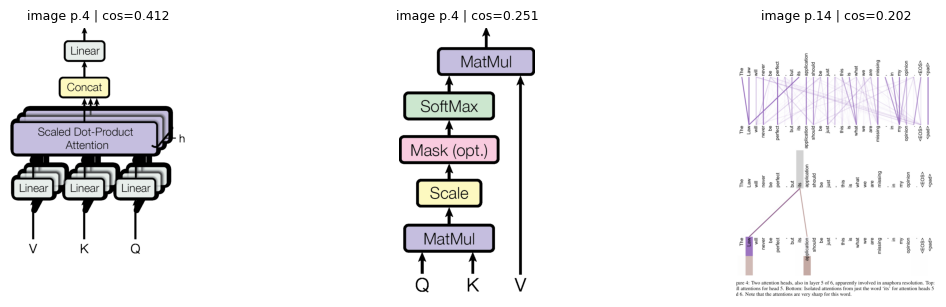

=== Requête image (1re image extraite) ===
[texte | p.6 | cos=0.329] no recurrence and no convolution, in order for the model to make use of the order of the sequence, we must inject some information about the relative or absolute position of the tokens in the sequence. To this end, we ad…
[texte | p.6 | cos=0.328] input embeddings at the bottoms of the encoder and decoder stacks. The positional encodings have the same dimension dmodel as the embeddings, so that the two can be summed. There are many choices of positional encodings,…
[texte | p.3 | cos=0.321] the encoder stack. Similar to the encoder, we employ residual connections around each of the sub-layers, followed by layer normalization. We also modify the self-attention sub-layer in the decoder stack to prevent positi…


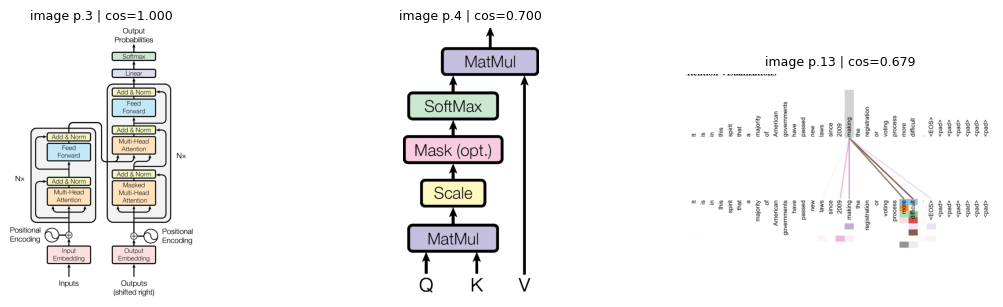

In [19]:
Query = Union[str, Path, Image.Image]

def search(query: Query, k: int = 3, modality: Literal["all", "text", "image"] = "all"):
    if isinstance(query, str):
        q = embed_texts([query])
    elif isinstance(query, (Path, Image.Image)):
        q = embed_images([query])
    else:
        raise TypeError("query doit être str (texte), Path ou PIL.Image")

    types = ["text", "image"] if modality == "all" else [modality]
    hits = []
    for t in types:
        res = collection.query(query_embeddings=q.tolist(), n_results=k,
                               where={"$and": [{"type": t}, {"doc_id": DOC_ID}]})
        for _id, doc, meta, dist in zip(res["ids"][0], res["documents"][0], res["metadatas"][0], res["distances"][0]):
            hits.append({"id": _id, "type": t, "score": 1.0 - dist, "page": meta["page"],
                         "text": doc, "image_path": meta["image_path"]})
    return hits

def show_results(hits, title=""):
    print(f"=== {title} ===")
    for h in (x for x in hits if x["type"] == "text"):
        print(f"[texte | p.{h['page']} | cos={h['score']:.3f}] {h['text'][:220]}…")
    imgs = [h for h in hits if h["type"] == "image"]
    if imgs:
        fig, axes = plt.subplots(1, len(imgs), figsize=(4.5 * len(imgs), 3.5), squeeze=False)
        for ax, h in zip(axes[0], imgs):
            ax.imshow(Image.open(h["image_path"])); ax.axis("off")
            ax.set_title(f"image p.{h['page']} | cos={h['score']:.3f}", fontsize=9)
        plt.show()

show_results(search("scaled dot-product attention", k=3), "Requête texte")
if image_records:
    show_results(search(Path(image_records[0]["path"]), k=3), "Requête image (1re image extraite)")

## Étape 5 — `retriever_tool`

L'outil expose la recherche à un LLM. Trois leviers pour bien le guider :
1. **La description** (docstring) : quand l'utiliser, quand ne pas l'utiliser, ce qu'il renvoie.
2. **Le schéma d'arguments** (`args_schema`) : types, valeurs autorisées et descriptions champ par champ.
3. **Le format de sortie** : un texte structuré avec page, score et chemin d'image, que le LLM peut citer.

In [20]:
from langchain_core.tools import tool
from pydantic import BaseModel, Field

class RetrieverInput(BaseModel):
    query: str = Field(default="", description="Requête en langage naturel (de préférence en anglais, "
                       "car le document est en anglais). Laisser vide si on cherche par image.")
    image_path: str = Field(default="", description="Chemin d'une image locale servant de requête "
                            "(recherche de figures ou de passages similaires). Laisser vide pour une requête texte.")
    modality: Literal["all", "text", "image"] = Field(default="all", description="'text' = passages, "
                      "'image' = figures/schémas, 'all' = les deux.")
    k: int = Field(default=3, ge=1, le=8, description="Nombre de résultats par modalité.")

@tool("retriever_tool", args_schema=RetrieverInput)
def retriever_tool(query: str = "", image_path: str = "", modality: str = "all", k: int = 3) -> str:
    """Recherche sémantique dans l'article « Attention Is All You Need » (architecture Transformer).
    Renvoie des passages de texte (avec numéro de page) et/ou des figures (chemin d'image, page, légende).
    À utiliser pour toute question sur le contenu de l'article : architecture, attention, hyperparamètres,
    résultats BLEU, entraînement, ou pour retrouver/identifier une figure. Accepte une requête texte OU une image.
    Ne pas l'utiliser pour les salutations ou les questions sans rapport avec l'article.
    Peut être rappelé avec une requête reformulée si les résultats sont insuffisants."""
    if image_path:
        p = Path(image_path)
        if not p.exists():
            return f"Erreur : image introuvable ({image_path})."
        hits = search(p, k=k, modality=modality)
    elif query.strip():
        hits = search(query, k=k, modality=modality)
    else:
        return "Erreur : fournir 'query' ou 'image_path'."

    lines = []
    for h in hits:
        if h["type"] == "text":
            lines.append(f"[TEXTE | page {h['page']} | cos={h['score']:.2f}] {h['text']}")
        else:
            lines.append(f"[IMAGE | page {h['page']} | cos={h['score']:.2f} | fichier={h['image_path']}] "
                         f"Légende(s) de la page : {h['text']}")
    return "\n".join(lines) if lines else "Aucun résultat."

print(retriever_tool.name, "|", retriever_tool.args)
print(retriever_tool.invoke({"query": "multi-head attention", "modality": "text", "k": 2}))

retriever_tool | {'query': {'default': '', 'description': 'Requête en langage naturel (de préférence en anglais, car le document est en anglais). Laisser vide si on cherche par image.', 'title': 'Query', 'type': 'string'}, 'image_path': {'default': '', 'description': "Chemin d'une image locale servant de requête (recherche de figures ou de passages similaires). Laisser vide pour une requête texte.", 'title': 'Image Path', 'type': 'string'}, 'modality': {'default': 'all', 'description': "'text' = passages, 'image' = figures/schémas, 'all' = les deux.", 'enum': ['all', 'text', 'image'], 'title': 'Modality', 'type': 'string'}, 'k': {'default': 3, 'description': 'Nombre de résultats par modalité.', 'maximum': 8, 'minimum': 1, 'title': 'K', 'type': 'integer'}}
[TEXTE | page 14 | cos=0.75] attention heads 5 and 6. Note that the attentions are very sharp for this word. 14
[TEXTE | page 14 | cos=0.66] just this is what we are missing , in my opinion . <EOS> <pad> Figure 4: Two attention heads,

## Étape 6 — Agent ReAct avec LangGraph

Architecture **MIND / BODY** :
- **MIND** (cerveau) : le LLM, lié à l'outil via `bind_tools`. Il raisonne et décide : appeler l'outil ou répondre.
- **BODY** (corps) : `ToolNode`, qui exécute l'action demandée par le MIND.

Boucle ReAct : `MIND (Reasoning) → BODY (Action) → retour au MIND (Observation) → … → réponse finale`. L'arête conditionnelle `tools_condition` route vers BODY si le LLM a émis un appel d'outil, sinon vers la fin.

In [21]:
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage, ToolMessage
from langgraph.graph import StateGraph, MessagesState, START, END
from langgraph.prebuilt import ToolNode, tools_condition

def get_llm(provider: str = os.getenv("LLM_PROVIDER", "ollama")):
    if provider == "ollama": 
        from langchain_ollama import ChatOllama
        return ChatOllama(model="qwen2.5:7b", temperature=0)
    raise ValueError(provider)

SYSTEM_PROMPT = """Tu es un assistant expert de l'article « Attention Is All You Need ».
Tu fonctionnes selon le schéma ReAct : réfléchis, agis avec l'outil si nécessaire, observe, puis conclus.
Règles :
- Pour toute question factuelle sur l'article, utilise retriever_tool avant de répondre ; n'invente jamais de chiffres.
- Si la question porte sur une figure, utilise modality='image' ou 'all'. Si l'utilisateur fournit une image, passe son chemin dans image_path.
- Tu peux appeler l'outil plusieurs fois avec des requêtes reformulées (en anglais) si les résultats sont insuffisants.
- Cite les numéros de page ; pour une figure, donne le chemin du fichier image.
- Pour une simple salutation ou une question hors sujet, réponds directement sans outil.
- Réponds dans la langue de l'utilisateur."""

llm = get_llm("ollama")
tools = [retriever_tool]
llm_with_tools = llm.bind_tools(tools)

def mind(state: MessagesState):
    """MIND : le LLM raisonne et décide d'appeler (ou non) l'outil."""
    return {"messages": [llm_with_tools.invoke([SystemMessage(SYSTEM_PROMPT)] + state["messages"])]}

body = ToolNode(tools)  # BODY : exécute retriever_tool

graph = StateGraph(MessagesState)
graph.add_node("mind", mind)
graph.add_node("body", body)
graph.add_edge(START, "mind")
graph.add_conditional_edges("mind", tools_condition, {"tools": "body", END: END})
graph.add_edge("body", "mind")  # Observation renvoyée au MIND
agent = graph.compile()

print(agent.get_graph().draw_mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	mind(mind)
	body(body)
	__end__([<p>__end__</p>]):::last
	__start__ --> mind;
	body --> mind;
	mind -.-> __end__;
	mind -. &nbsp;tools&nbsp; .-> body;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



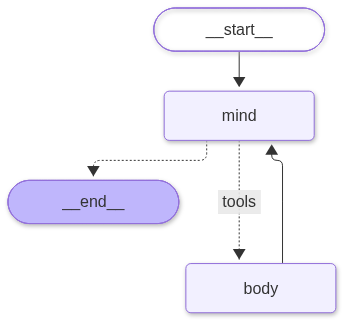

In [22]:
# Rendu du graphe (facultatif)
try:
    from IPython.display import Image as IPImage, display
    display(IPImage(agent.get_graph().draw_mermaid_png()))
except Exception as e:
    print("Rendu PNG indisponible (utiliser le code Mermaid ci-dessus) :", type(e).__name__)

## Étape 7 — Tests et analyse du comportement

`ask()` rejoue la trace complète : **Thought/Action** (appel d'outil décidé par le MIND), **Observation** (retour du BODY) et **réponse finale**. Elle renvoie aussi les appels d'outil pour l'analyse.

In [23]:
def _text(content) -> str:
    if isinstance(content, str):
        return content
    return " ".join(b.get("text", "") for b in content if isinstance(b, dict) and b.get("type") == "text")

def ask(question: str, image_path: str | None = None, verbose: bool = True):
    content = question if not image_path else f"{question}\n\n[Image fournie par l'utilisateur : {image_path}]"
    tool_calls, answer = [], ""
    print("\n" + "=" * 90 + f"\n❓ {question}" + (f"  (+ image {image_path})" if image_path else ""))
    for step in agent.stream({"messages": [HumanMessage(content)]}, config={"recursion_limit": 14}, stream_mode="updates"):
        for node, update in step.items():
            for m in update["messages"]:
                if isinstance(m, AIMessage) and m.tool_calls:
                    if verbose and _text(m.content).strip():
                        print(f"🧠 THOUGHT : {_text(m.content).strip()[:300]}")
                    for tc in m.tool_calls:
                        tool_calls.append(tc["args"])
                        print(f"🔧 ACTION  : {tc['name']}({tc['args']})")
                elif isinstance(m, ToolMessage):
                    if verbose:
                        print(f"👁️  OBSERVATION : {m.content[:350].replace(chr(10), ' ')}…")
                elif isinstance(m, AIMessage):
                    answer = _text(m.content)
    print(f"✅ RÉPONSE FINALE :\n{answer}")
    return {"question": question, "tool_calls": tool_calls, "answer": answer}

In [24]:
sample_image = image_records[0]["path"] if image_records else None

tests = [
    # 1. Pas d'outil attendu : l'agent doit décider de ne PAS chercher
    dict(question="Bonjour ! Peux-tu te présenter en une phrase ?"),
    # 2. Recherche texte factuelle
    dict(question="Quel score BLEU le Transformer (big) obtient-il sur WMT 2014 English-to-German et English-to-French ?"),
    # 3. Hybride texte + image : explication ET figure correspondante
    dict(question="Explique le mécanisme de multi-head attention et montre-moi la figure qui l'illustre."),
    # 4. Multi-étapes : plusieurs recherches attendues
    dict(question="Compare l'encodeur et le décodeur : nombre de couches, sous-couches, et rôle du masquage."),
]
if sample_image:
    # 5. Requête par image
    tests.append(dict(question="À quelle partie de l'article correspond cette image, et que dit le texte à son sujet ?",
                      image_path=sample_image))

results = [ask(**t) for t in tests]


❓ Bonjour ! Peux-tu te présenter en une phrase ?
✅ RÉPONSE FINALE :
Bonjour ! Je suis un assistant basé sur l'article "Attention Is All You Need", prêt à répondre à toutes vos questions sur ce sujet.

❓ Quel score BLEU le Transformer (big) obtient-il sur WMT 2014 English-to-German et English-to-French ?
🔧 ACTION  : retriever_tool({'k': 1, 'modality': 'text', 'query': 'BLEU score WMT 2014 English-to-German and English-to-French'})
👁️  OBSERVATION : [TEXTE | page 1 | cos=0.71] models to be superior in quality while being more parallelizable and requiring significantly less time to train. Our model achieves 28.4 BLEU on the WMT 2014 Englishto-German translation task, improving over the existing best results, including ensembles, by over 2 BLEU. On the WMT 2014 English-to-French translation task…
✅ RÉPONSE FINALE :
Le modèle Transformer (big) obtient un score BLEU de 28.4 sur la tâche d'English-to-German pour WMT 2014 et 41.8 sur la tâche d'English-to-French pour WMT 2014.

❓ Explique le 

In [25]:
# Synthèse : l'agent a-t-il décidé d'appeler l'outil, et combien de fois ?
print(f"{'#':<3}{'appels outil':<14}{'modalités demandées':<28}question")
for i, r in enumerate(results, 1):
    mods = sorted({c.get("modality", "all") for c in r["tool_calls"]}) or ["—"]
    print(f"{i:<3}{len(r['tool_calls']):<14}{','.join(mods):<28}{r['question'][:60]}")

#  appels outil  modalités demandées         question
1  0             —                           Bonjour ! Peux-tu te présenter en une phrase ?
2  1             text                        Quel score BLEU le Transformer (big) obtient-il sur WMT 2014
3  1             all                         Explique le mécanisme de multi-head attention et montre-moi 
4  1             text                        Compare l'encodeur et le décodeur : nombre de couches, sous-
5  1             image                       À quelle partie de l'article correspond cette image, et que 


### Grille d'analyse

| Test | Comportement attendu |
|---|---|
| 1. Salutation | 0 appel d'outil (le MIND répond directement) |
| 2. Chiffres BLEU | ≥ 1 appel `modality='text'` ou `all`, réponse avec numéro de page, pas de chiffre inventé |
| 3. Hybride | Appel avec `modality='all'` (ou 2 appels texte + image), réponse citant la figure retrouvée |
| 4. Comparaison | ≥ 2 appels avec des requêtes reformulées (boucle ReAct multi-tours) |
| 5. Image en requête | Appel avec `image_path` renseigné |

**Limites connues à discuter dans le rapport** : CLIP est entraîné sur des paires image-légende, pas sur du texte scientifique (la recherche texte→texte est correcte mais moins fine qu'un modèle d'embedding textuel dédié) ; chunks courts à cause des 77 tokens ; le *modality gap* oblige à classer par modalité ; le LLM reçoit le chemin des images mais ne les « voit » pas, sauf à lui passer l'image en entrée si le modèle est multimodal.